In [ ]:
!pip install -q transformers

In [ ]:
from transformers import ViTImageProcessor, ViTForImageClassification

model_name = "google/vit-base-patch16-224"

processor = ViTImageProcessor.from_pretrained(model_name)
model = ViTForImageClassification.from_pretrained(model_name)

print("Model imported successfully!")

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Model imported successfully!


In [ ]:
!pip install -q tensorflow-datasets

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
ZIP_PATH = "/content/drive/MyDrive/kagglecatsanddogs_5340.zip"

EXTRACT_PATH = "/content/drive/MyDrive/Cats_Dogs_Dataset"

In [ ]:
import zipfile
import os

if os.path.exists(ZIP_PATH):

    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(EXTRACT_PATH)

    print("Dataset extracted successfully!")

else:
    print("ZIP file not found. Check your Google Drive path.")

Dataset extracted successfully!


In [ ]:
for root, dirs, files in os.walk(EXTRACT_PATH):
    print("Folder:", root)
    print("Subfolders:", dirs)
    print("Number of files:", len(files))

    if root.count(os.sep) > 5:
        dirs[:] = []

Folder: /content/drive/MyDrive/Cats_Dogs_Dataset
Subfolders: ['PetImages']
Number of files: 2
Folder: /content/drive/MyDrive/Cats_Dogs_Dataset/PetImages
Subfolders: ['Cat', 'Dog']
Number of files: 0
Folder: /content/drive/MyDrive/Cats_Dogs_Dataset/PetImages/Cat
Subfolders: []
Number of files: 12501
Folder: /content/drive/MyDrive/Cats_Dogs_Dataset/PetImages/Dog
Subfolders: []
Number of files: 12501


In [ ]:
import os
import torch
import numpy as np

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

DATASET_PATH = "/content/drive/MyDrive/Cats_Dogs_Dataset/PetImages"

print("Dataset path configured successfully!")

Dataset path configured successfully!


In [ ]:
cat_path = os.path.join(DATASET_PATH, "Cat")
dog_path = os.path.join(DATASET_PATH, "Dog")

cat_images = [
    f for f in os.listdir(cat_path)
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
]

dog_images = [
    f for f in os.listdir(dog_path)
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
]

print("Cat images:", len(cat_images))
print("Dog images:", len(dog_images))
print("Total images:", len(cat_images) + len(dog_images))

Cat images: 12500
Dog images: 12500
Total images: 25000


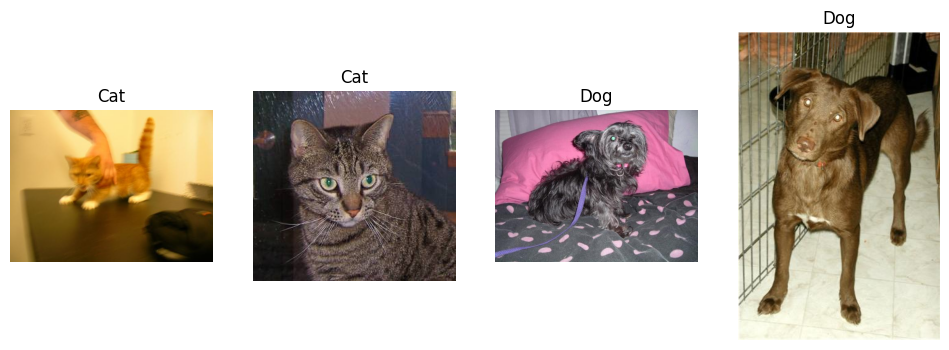

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(12, 4))

for i in range(2):
    img = Image.open(os.path.join(cat_path, cat_images[i])).convert("RGB")
    axes[i].imshow(img)
    axes[i].set_title("Cat")
    axes[i].axis("off")

for i in range(2):
    img = Image.open(os.path.join(dog_path, dog_images[i])).convert("RGB")
    axes[i+2].imshow(img)
    axes[i+2].set_title("Dog")
    axes[i+2].axis("off")

plt.show()

In [ ]:
from transformers import ViTImageProcessor, ViTForImageClassification

MODEL_NAME = "google/vit-base-patch16-224"

processor = ViTImageProcessor.from_pretrained(MODEL_NAME)

model = ViTForImageClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    ignore_mismatched_sizes=True,
    id2label={0: "Cat", 1: "Dog"},
    label2id={"Cat": 0, "Dog": 1}
)

print("ViT model ready for fine-tuning!")

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `1000`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([2, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([2])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


ViT model ready for fine-tuning!


In [ ]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=processor.image_mean,
        std=processor.image_std
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=processor.image_mean,
        std=processor.image_std
    )
])

print("Image transformations ready!")

Image transformations ready!


In [ ]:
from torchvision.datasets import ImageFolder
from torch.utils.data import random_split, DataLoader

dataset = ImageFolder(
    root="/content/drive/MyDrive/Cats_Dogs_Dataset/PetImages",
    transform=train_transform
)

print("Classes:", dataset.classes)
print("Total images:", len(dataset))

Classes: ['Cat', 'Dog']
Total images: 25000


In [ ]:
import os
import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

DATASET_PATH = "/content/drive/MyDrive/Cats_Dogs_Dataset/PetImages"

# Collect valid image paths
image_paths = []
labels = []

for label, class_name in enumerate(["Cat", "Dog"]):
    folder = os.path.join(DATASET_PATH, class_name)

    for filename in os.listdir(folder):
        path = os.path.join(folder, filename)

        try:
            with Image.open(path) as img:
                img.verify()
            image_paths.append(path)
            labels.append(label)
        except:
            pass

# Split: 80% training, 20% testing
train_paths, test_paths, train_labels, test_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

print("Valid images:", len(image_paths))
print("Training images:", len(train_paths))
print("Testing images:", len(test_paths))

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Valid images: 24998
Training images: 19998
Testing images: 5000


In [ ]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image

class CatsDogsDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        image = Image.open(self.paths[index]).convert("RGB")
        image = self.transform(image)
        label = self.labels[index]

        return image, label


train_dataset = CatsDogsDataset(
    train_paths, train_labels, train_transform
)

test_dataset = CatsDogsDataset(
    test_paths, test_labels, test_transform
)

train_loader = DataLoader(
    train_dataset, batch_size=16, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=16, shuffle=False
)

print("Training and testing DataLoaders are ready!")

Training and testing DataLoaders are ready!


In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)

print("Device:", device)
print("Model is ready for fine-tuning!")

Device: cuda
Model is ready for fine-tuning!


In [ ]:
from torch.optim import AdamW

optimizer = AdamW(model.parameters(), lr=2e-5)

loss_function = torch.nn.CrossEntropyLoss()

print("Optimizer and loss function are ready!")

Optimizer and loss function are ready!


In [ ]:
EPOCHS = 3

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(pixel_values=images)
        loss = loss_function(outputs.logits, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)

    print(
        f"Epoch {epoch+1}/{EPOCHS} - "
        f"Training Loss: {average_loss:.4f}"
    )

print("Fine-tuning completed!")

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Epoch 1/3 - Training Loss: 0.0274
Epoch 2/3 - Training Loss: 0.0050
Epoch 3/3 - Training Loss: 0.0049
Fine-tuning completed!


In [ ]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(pixel_values=images)
        predictions = torch.argmax(outputs.logits, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 99.72%


In [ ]:
SAVE_PATH = "/content/drive/MyDrive/FineTuned_ViT_CatsDogs"

model.save_pretrained(SAVE_PATH)
processor.save_pretrained(SAVE_PATH)

print("Fine-tuned model saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Fine-tuned model saved successfully!


In [3]:
from huggingface_hub import notebook_login

notebook_login()

In [4]:
from huggingface_hub import HfApi

api = HfApi()

USERNAME = "Sohaila16"
REPO_NAME = "cats-dogs-vit-classifier"

api.create_repo(
    repo_id=f"{USERNAME}/{REPO_NAME}",
    repo_type="model",
    exist_ok=True
)

print("Hugging Face repository created successfully!")

Hugging Face repository created successfully!


In [8]:
api.upload_folder(
    folder_path="/content/drive/MyDrive/FineTuned_ViT_CatsDogs",
    repo_id="Sohaila16/cats-dogs-vit-classifier",
    repo_type="model"
)

print("Model uploaded successfully!")

Model uploaded successfully!
